## FSHD test: case ONT026

In [1]:
##### Basic information #####
PREFIX="ONT026"

In [2]:
### Importing modules ###
import os
import multiprocessing
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

### DIRECTORIES ###
TMP = "/raid/tmp/fshd"
QUERY = "/lab_nas_home_user/Mark/FSHD/querySeq"

### Resources ###
cores = int(multiprocessing.cpu_count() * 0.75)

### Softwares ###
BLASTN = "/Everythings/misc/ncbi-blast-2.13.0+/bin/blastn"
MAKEBLASTDB = "/Everythings/misc/ncbi-blast-2.13.0+/bin/makeblastdb"
MODKIT = "/Everythings/misc/modkit_v0.2.4/modkit"

In [12]:
### Path to BAM file ###
directory="/nanopore_nas/nanopore_pipeline"
matching_folder = next(folder for folder in os.listdir(directory) if PREFIX in folder)
BAM = os.path.join(directory, matching_folder, 'RAW', matching_folder+"_raw.cram")

In [4]:
### Prettify the output ###
blast_title = ['QuerySeq-id', 'Seq-id', 'Identity%', 'Alignment-length', 'Mismatches', 'Gap', 'Q.Start', 'Q.End', 'S.Start', 'S.End', 'E-value', 'Bit-score']

In [14]:
### Create fasta file from BAM file, extract reads mapped to chr4 ###
if not os.path.exists(TMP):
    os.makedirs(TMP)
os.system("samtools view -b "+BAM+" chr4 | samtools fasta - > "+TMP+"/"+PREFIX+"_chr4.fasta")

[M::bam2fq_mainloop] discarded 0 singletons
[M::bam2fq_mainloop] processed 882760 reads


0

In [15]:
### Create BLAST database ###
os.system(MAKEBLASTDB+" -in "+TMP+"/"+PREFIX+"_chr4.fasta -dbtype nucl -out "+TMP+"/blastdb/chr4 -title "+PREFIX)



Building a new DB, current time: 03/12/2025 11:48:30
New DB name:   /raid/tmp/fshd/blastdb/chr4
New DB title:  ONT026
Sequence type: Nucleotide
Keep MBits: T
Maximum file size: 3000000000B
Adding sequences from FASTA; added 882760 sequences in 65.0561 seconds.




0

Get sequence ID with tail sequence (pLAM)

In [16]:
### Find reads have tail sequence (pLAM) ###
os.system(BLASTN+" -db "+TMP+"/blastdb/chr4 -query "+QUERY+"/pLAM.fasta -out "+TMP+"/"+PREFIX+"_pLAM.blast -num_threads "+str(cores)+" -outfmt 6")

# Load result
pLAM_blast = (
    pd.read_table(TMP+"/"+PREFIX+"_pLAM.blast", header=None, sep="\t", names=blast_title)
        .drop(columns=['QuerySeq-id'])
        .sort_values(by='Identity%', ascending=False)
)
pLAM_blast.head()

,Seq-id,Identity%,Alignment-length,Mismatches,Gap,Q.Start,Q.End,S.Start,S.End,E-value,Bit-score
1,28fd356a-0f91-490d-9c9d-0db0ab88d6ab,100.000,192,0,0,9,200,9471,9280,1.060000e-95,355
0,ab041dad-9682-4e87-8a9a-c90893e3c353,99.000,200,1,1,1,200,2597,2795,2.940000e-96,357
2,9cdbf7f3-6e13-44b1-96c5-9278ab275b07,98.500,200,3,0,1,200,1194,1393,3.810000e-95,353
3,7193de3d-3658-44af-9961-8eacf4e5fa64,98.000,200,4,0,1,200,2080,1881,1.770000e-93,348
6,fc6ce699-1bc5-4b62-9972-e4a187d09ae4,84.375,192,29,1,1,191,1776,1967,4.080000e-45,187


Get sequence ID with head sequence (P13E11)

In [17]:
### Find reads have head sequence (P13E11) ###
os.system(BLASTN+" -db "+TMP+"/blastdb/chr4 -query "+QUERY+"/P13E11.fasta -out "+TMP+"/"+PREFIX+"_P13E11.blast -num_threads "+str(cores)+" -outfmt 6")

# Load result
P13E11_blast = (
    pd.read_table(TMP+"/"+PREFIX+"_P13E11.blast", header=None, sep="\t", names=blast_title)
        .drop(columns=['QuerySeq-id'])
        .sort_values(by='Identity%', ascending=False)
)
P13E11_blast.head()

,Seq-id,Identity%,Alignment-length,Mismatches,Gap,Q.Start,Q.End,S.Start,S.End,E-value,Bit-score
0,2e4e35a8-2557-4064-b88f-b48b5beacd2b,100.0,220,0,0,1,220,842,623,3.220000e-111,407
1,d54eb5df-0fa2-4f41-b8bc-b385716da0f2,100.0,220,0,0,1,220,2212,2431,3.220000e-111,407
2,523242df-08d6-4fb3-95d8-04c24ab8fe9c,100.0,220,0,0,1,220,278,59,3.220000e-111,407
3,166cfaf0-1954-45ae-ba98-ba7229b08f31,100.0,220,0,0,1,220,482,263,3.220000e-111,407
4,79382318-c408-435f-900c-23bad95ea6e4,100.0,220,0,0,1,220,13331,13550,3.220000e-111,407


Count D4Z4 repeat units

In [29]:
### Find reads have D4Z4 ###
os.system(BLASTN+" -db "+TMP+"/blastdb/chr4 -query "+QUERY+"/MIR8078.fasta -out "+TMP+"/"+PREFIX+"_D4Z4.blast -num_threads "+str(cores)+" -outfmt 6")

# Load result
D4Z4_blast = (
    pd.read_table(TMP+"/"+PREFIX+"_D4Z4.blast", header=None, sep="\t", names=blast_title)
        .drop(columns=['QuerySeq-id'])
        .sort_values(by='Identity%', ascending=False)
)

# Count number of reads, grouped by Seq-id
D4Z4_count = D4Z4_blast.groupby('Seq-id').size().reset_index(name='Count').sort_values(by='Count', ascending=False)
print(D4Z4_count.head())

                                  Seq-id  Count
68  80767cec-2842-4666-8ff2-eed65b70093e     23
37  44d4c8c5-3909-40e8-8d75-202f6bfb55b7     19
73  8638395c-e34a-4d2e-92f0-bcb6c27b8d82     14
44  5297e858-bcbe-45a9-b046-c0132c3b6706     13
70  83986fe7-3228-494c-bbc4-168b074ee6f2     13


Count D4Z4 repeats having **EITHER head OR tail**

In [30]:
# Find unique sequences from the first column of both pLAM_blast and P13E11_blast
unique_sequences = set(pLAM_blast['Seq-id']).union(set(P13E11_blast['Seq-id']))

if len(unique_sequences) == 0:
    print("No unique sequences found.")
else:
    # Extract rows from D4Z4_count where Seq-id is in unique_sequences
    count_head_or_tail = D4Z4_count[D4Z4_count['Seq-id'].isin(unique_sequences)]
    print(count_head_or_tail)

                                   Seq-id  Count
44   5297e858-bcbe-45a9-b046-c0132c3b6706     13
70   83986fe7-3228-494c-bbc4-168b074ee6f2     13
24   28fd356a-0f91-490d-9c9d-0db0ab88d6ab     13
75   8a6e8e20-6937-4dbc-9657-0df8a019ea2c     12
89   afde9dcb-d5f4-4b64-9af8-8068422ba387     12
0    003310aa-3de9-446b-adbf-a139a3447dcb      9
32   2fda7a3e-0a24-445f-8aa4-d44e01134ff9      7
115  e6280cc6-61a3-461b-8c7e-243197396b80      7
19   1dfe9486-c5de-481c-9c3b-443a1cacbccd      6
20   1eee3530-8926-4c98-81a2-d17aad3595cf      4
65   79382318-c408-435f-900c-23bad95ea6e4      3
125  fb878d1f-e5e8-471f-b34f-e8599871cc40      2
59   705617dc-9ed2-4685-8613-675a5a96f660      2
61   7193de3d-3658-44af-9961-8eacf4e5fa64      1
51   624dc47a-9194-4136-8d5b-971c1c207e1a      1
3    02b85c43-30f4-4d5d-a851-f15bef8a2b43      1
87   ab041dad-9682-4e87-8a9a-c90893e3c353      1
84   9cdbf7f3-6e13-44b1-96c5-9278ab275b07      1


Count D4Z4 repeats having **BOTH head AND tail**

In [31]:
# Find sequences from the first column in both pLAM_blast and P13E11_blast
common_sequences = set(pLAM_blast['Seq-id']).intersection(set(P13E11_blast['Seq-id']))

if len(common_sequences) == 0:
    print("No sequences found.")
else: 
    # Extract rows from D4Z4_count where Seq-id is in common_sequences
    count_head_and_tail = D4Z4_count[D4Z4_count['Seq-id'].isin(common_sequences)]
    print(count_head_and_tail)

No sequences found.


Check polyA tail

In [40]:
### Find reads have tail sequence (pLAM) ###
os.system(BLASTN+" -db "+TMP+"/blastdb/chr4 -query "+QUERY+"/pLAM-polyA.fasta -out "+TMP+"/"+PREFIX+"_pLAM_polyA.blast -num_threads "+str(cores)+" -outfmt 6")

# Load result
pLAM_polyA_blast = (
    pd.read_table(TMP+"/"+PREFIX+"_pLAM_polyA.blast", header=None, sep="\t", names=blast_title)
        .sort_values(by='Identity%', ascending=False)
)

# Pivot the dataframe to have hapA and hapB mismatches in separate columns
pivot_df = pLAM_polyA_blast.pivot(index='Seq-id', columns='QuerySeq-id', values='Mismatches')
pivot_df.rename(columns={'hapA': 'hapA.Mismatches', 'hapB': 'hapB.Mismatches'}, inplace=True)

# Calculate the difference in mismatches between hapA and hapB
pivot_df['delta.Mismatches'] =  pivot_df['hapB.Mismatches'] - pivot_df['hapA.Mismatches']

# Permissive column to indicate if the sequence is hapA, hapB, or unknown
pivot_df['Permissive'] = pivot_df['delta.Mismatches'].apply(lambda x: 'hapA' if x == 1 else 'hapB' if x == -1 else 'Unknown')

# Reset the index to make 'Seq-id' a column again
result_df = pivot_df.reset_index()
result_df.columns.name = None

# Display the result
print(result_df)

                                 Seq-id  hapA.Mismatches  hapB.Mismatches  \
0  1f695989-800a-439d-aee4-13b2482cbabd               32               31   
1  28fd356a-0f91-490d-9c9d-0db0ab88d6ab                0                1   
2  624dc47a-9194-4136-8d5b-971c1c207e1a               31               30   
3  7193de3d-3658-44af-9961-8eacf4e5fa64                4                5   
4  9cdbf7f3-6e13-44b1-96c5-9278ab275b07                3                4   
5  ab041dad-9682-4e87-8a9a-c90893e3c353                1                2   
6  fc6ce699-1bc5-4b62-9972-e4a187d09ae4               29               28   

   delta.Mismatches Permissive  
0                -1       hapB  
1                 1       hapA  
2                -1       hapB  
3                 1       hapA  
4                 1       hapA  
5                 1       hapA  
6                -1       hapB  


Calculate methylation level

In [36]:
### Extract reads with tail by sequence ID from pLAM_blast ###
pLAM_blast['Seq-id'].to_csv(TMP + "/" + PREFIX + "_tail_ids.txt", index=False, header=False)
os.system("samtools view -b --qname-file /raid/tmp/fshd/ONT026_tail_ids.txt -o /raid/tmp/fshd/ONT026_tail.bam /nanopore_nas/nanopore_pipeline/WGS-ONT026-6838397-D26075/43.longphase/WGS-ONT026-6838397-D26075.sorted.phased.cram")
os.system("samtools index "+TMP+"/"+PREFIX+"_tail.bam")
os.system("rsync -a "+TMP+"/"+PREFIX+"_tail.bam* /lab_nas_home_user/Mark/FSHD/tail_bams/")

### Extract CpG methylation information ###
os.system(MODKIT+" pileup "+TMP+"/"+PREFIX+"_tail.bam "+TMP+"/"+PREFIX+"_CpG.txt --cpg --ignore h --combine-strands --ref /lab_nas_home_user/Mark/reference_genome/hg38/genome.fasta")

> calculated chunk size: 6, interval size 100000, processing 600000 positions concurrently
> ignoring mod code h
> filtering to only CpG motifs
> attempting to sample 10042 reads
> Using filter threshold 0.7529297 for C.
> Done, processed 2701 rows. Processed ~7 reads and skipped zero reads.


0

In [37]:
cpg_title=["chrom", "start", "end", "score", "N_validCov", "N_mod", "FracMod"]
cpg = pd.read_table(TMP+"/"+PREFIX+"_CpG.txt", header=None, sep="\s+").iloc[:, [0, 1, 2, 4, 9, 11, 10]]
cpg.columns = cpg_title
cpg.head()

,chrom,start,end,score,N_validCov,N_mod,FracMod
0,chr4,190065229,190065230,1,1,1,100.0
1,chr4,190065231,190065232,1,1,1,100.0
2,chr4,190065259,190065260,1,1,0,0.0
3,chr4,190065273,190065274,1,1,1,100.0
4,chr4,190065280,190065281,1,1,1,100.0


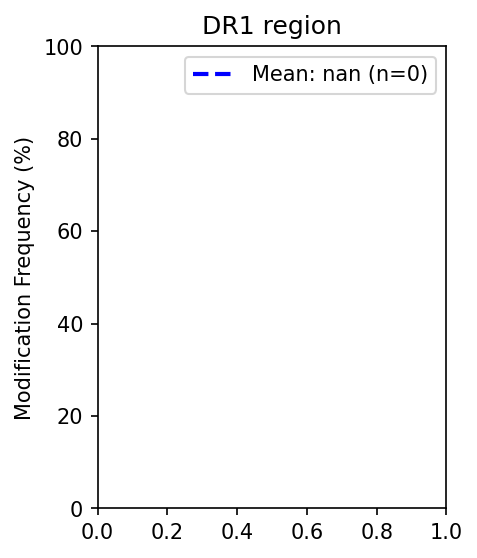

In [38]:
# DR1 region (hg38, chr4:190086470-190086723)
dr1_region = cpg[(cpg['chrom'] == 'chr4') & (cpg['start'] >= 190086470) & (cpg['end'] <= 190086723)]

# Remove rows where N_validCov is equal to 1
dr1_region_filtered = dr1_region[dr1_region['N_validCov'] != 1]

plt.figure(figsize=(3, 4), dpi=150)
sns.boxplot(y='FracMod', data=dr1_region_filtered, orient='v')
plt.title('DR1 region')
plt.ylabel('Modification Frequency (%)')
plt.ylim(0, 100)  # Set y-axis range from 0 to 100

# Calculate the mean value of FracMod
mean_fracmod_dr1 = dr1_region_filtered['FracMod'].mean()

# Add a red horizontal line at the mean value
plt.axhline(mean_fracmod_dr1, color='blue', linestyle='--', linewidth=2, label=f'Mean: {mean_fracmod_dr1:.2f} (n={len(dr1_region_filtered)})')
plt.legend()

plt.show()


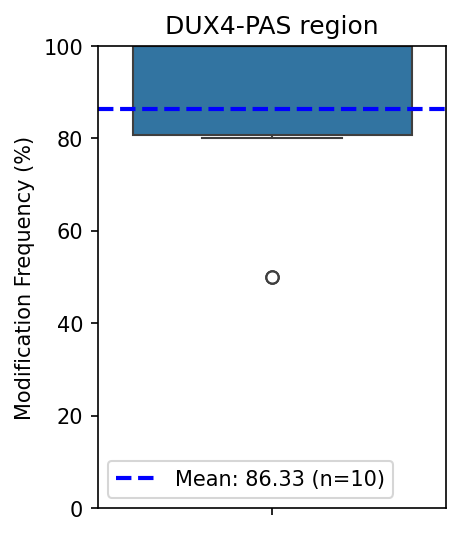

In [39]:
# DUX4-PAS region (hg38, chr4:190175600-190175834)
dux4pas = cpg[(cpg['chrom'] == 'chr4') & (cpg['start'] >= 190175600) & (cpg['end'] <= 190175834)]

# Remove rows where N_validCov is equal to 1
dux4pas_filtered = dux4pas[dux4pas['N_validCov'] != 1]

plt.figure(figsize=(3, 4), dpi=150)
sns.boxplot(y='FracMod', data=dux4pas_filtered, orient='v')
plt.title('DUX4-PAS region')
plt.ylabel('Modification Frequency (%)')
plt.ylim(0, 100)  # Set y-axis range from 0 to 100

# Calculate the mean value of FracMod
mean_fracmod = dux4pas_filtered['FracMod'].mean()

# Add a red horizontal line at the mean value
plt.axhline(mean_fracmod, color='blue', linestyle='--', linewidth=2, label=f'Mean: {mean_fracmod:.2f} (n={len(dux4pas_filtered)})')
plt.legend()

plt.show()


In [3]:
### Remove tmp files
os.system("rm -r "+TMP+"/*")

0